In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import os
from tqdm import tqdm


from catboost import CatBoostRegressor, cv, Pool
import shap

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# Load Data

In [37]:
train = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv", index_col="Id")
test = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv", index_col="Id")

X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

# Unused Features

# Null Values

In [38]:
from sklearn.base import BaseEstimator, TransformerMixin

class LotFrontageImputer(BaseEstimator, TransformerMixin):
    def __init(self):
        pass
        
    def fit(self, X, y=None):
        self.means_ = X.groupby(["Neighborhood"])["LotFrontage"].mean()
        self.global_mean_ = X["LotFrontage"].mean()
        return self

    def transform(self, X):
        x = X.copy()
        neighborhood_means = x["Neighborhood"].map(self.means_)
        neighborhood_means = neighborhood_means.fillna(self.global_mean_)
        x["LotFrontage"] = x["LotFrontage"].fillna(neighborhood_means)
        return x

In [39]:
def handle_null_values(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    # From the data_description.txt file, NaNs mean absence of
    x["PoolQC"] = x["PoolQC"].replace(np.nan, "No Pool")
    x["MiscFeature"] = x["MiscFeature"].replace(np.nan, "All Covered")
    x["Alley"] = x["Alley"].replace(np.nan, "No Alley Access")
    x["Fence"] = x["Fence"].replace(np.nan, "No Fence")
    x["FireplaceQu"] = x["FireplaceQu"].replace(np.nan, "No Fireplace")
    x["GarageType"] = x["GarageType"].replace(np.nan, "No Garage")
    x["GarageYrBlt"] = x["GarageYrBlt"].replace(np.nan, -1)
    x["GarageFinish"] = x["GarageFinish"].replace(np.nan, "No Garage")
    x["GarageQual"] = x["GarageQual"].replace(np.nan, "No Garage")
    x["GarageCond"] = x["GarageCond"].replace(np.nan, "No Garage")

    # Logical Values
    x.loc[x["MasVnrArea"] < 5, "MasVnrArea"] = 0 # We account for typos in the Area
    x["MasVnrArea"] = x["MasVnrArea"].fillna(0) # When MasVnrArea is Null, MasVnrType is also Null so we can assume absence
    x["MasVnrType"] = x["MasVnrType"].fillna("No Masonry")
    mask = (x["MasVnrArea"] == 0) & (x["MasVnrType"] != "No Masonry")
    x.loc[mask, "MasVnrType"] = "No Masonry"

    mask = (x["BsmtFinType1"].isna()) & (x["BsmtFinType2"].isna()) & (x["BsmtExposure"].isna()) & (x["BsmtCond"].isna()) & (x["BsmtQual"].isna())
    x.loc[mask, ["BsmtFinType1", "BsmtFinType2", "BsmtExposure", "BsmtCond", "BsmtQual"]] = "No Basement"
    
    # Ilogical Values
    mask = (x["MasVnrArea"] > 15) & (x["MasVnrType"] == "No Masonry")
    x.loc[mask, "MasVnrType"] = np.nan

    return x

In [45]:
def handle_low_variance_features(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
 
    x["BsmtFullBath"], x["BsmtHalfBath"] = x["BsmtFullBath"].clip(upper=2), x["BsmtHalfBath"].clip(upper=1)
    x["IsLotFrontageNull"] = x["LotFrontage"].isna()
    x["YearRemodAddGap"] = x["YearRemodAdd"] - x["YearBuilt"]
    
    drop_vars = [
        "MiscVal", # Stands for Miscellaneous Features Value. Very skewed distribution towards 0, maybe consider converting it to a flag
        "Electrical", # Many samples on only one category. There is other category with 100 samples that shows less mean SalePrice, but might be noise. Consider leave it in
        "Utilities", # On the training set, there is only one sample not in the main category
        "PoolQC", "PoolArea", # Very skewed distributions, and using a flag HasPool didn't improve the performance
        "Exterior2nd", # Highly correlated to Exterior1st (Cramér's V and MI of ~0.8). We saw an improvement in performance
        "GarageQual" # Highly correlated to Exterior1st (Cramér's V and MI of ~0.7). We saw an improvement in performance
    ]
    x = x.drop(columns=drop_vars)

    return x

In [46]:
wf = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("handle_low_variance_features", FunctionTransformer(handle_low_variance_features))
])

# Predictions

In [47]:
X_trans = wf.fit_transform(X)

cat_vars = X_trans.select_dtypes("object").columns
X_trans[cat_vars] = X_trans[cat_vars].fillna("Missing")
X_trans[cat_vars] = X_trans[cat_vars].astype("category") # Catboost doesn't distinguish between category or object dtype, but XGBoost and LightGBM do

train_pool = Pool(data=X_trans, label=y, cat_features=cat_vars.tolist())

model = CatBoostRegressor(random_state=42, cat_features=cat_vars.tolist(), verbose=False)
# model.fit(train_pool)

params = {
    "loss_function": "RMSE",
    "eval_metric": "RMSE",
    "custom_metric": ["R2"],
    "random_seed": 42,
    "verbose": 0,
    "task_type": "GPU"
}

cv_scores = cv(
    pool = train_pool,
    params = params,
    fold_count = 5,
    shuffle = True,
    partition_random_seed = 42
)

best_iteration = cv_scores["test-RMSE-mean"].idxmin()
print(f"Best Iteration: {best_iteration}")

best_rmse = cv_scores["test-RMSE-mean"].iloc[best_iteration]
best_r2 = cv_scores["test-R2-mean"].iloc[best_iteration]

print(f"Best Validation RMSE: {best_rmse:.4f}")
print(f"Best Validation R²:   {best_r2:.4f}")

Default metric period is 5 because R2 is/are not implemented for GPU
Metric R2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


Training on fold [0/5]
bestTest = 28148.22967
bestIteration = 999
Training on fold [1/5]


Metric R2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


bestTest = 27728.03535
bestIteration = 999
Training on fold [2/5]


Metric R2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


bestTest = 22408.89436
bestIteration = 999
Training on fold [3/5]


Metric R2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


bestTest = 31017.75517
bestIteration = 999
Training on fold [4/5]


Metric R2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


bestTest = 28680.81078
bestIteration = 690
Best Iteration: 200
Best Validation RMSE: 27614.7098
Best Validation R²:   0.8783


Running Feature Selection: 100%|██████████| 50/50 [28:55<00:00, 34.72s/it]


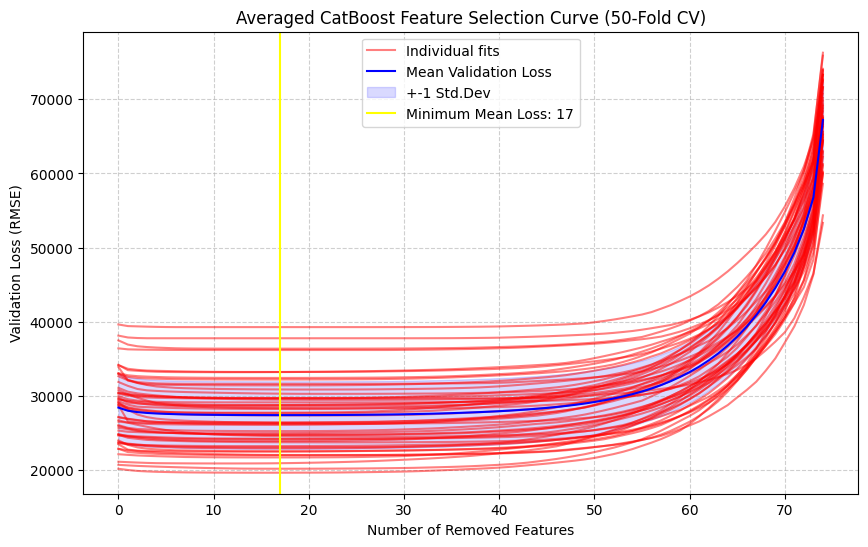

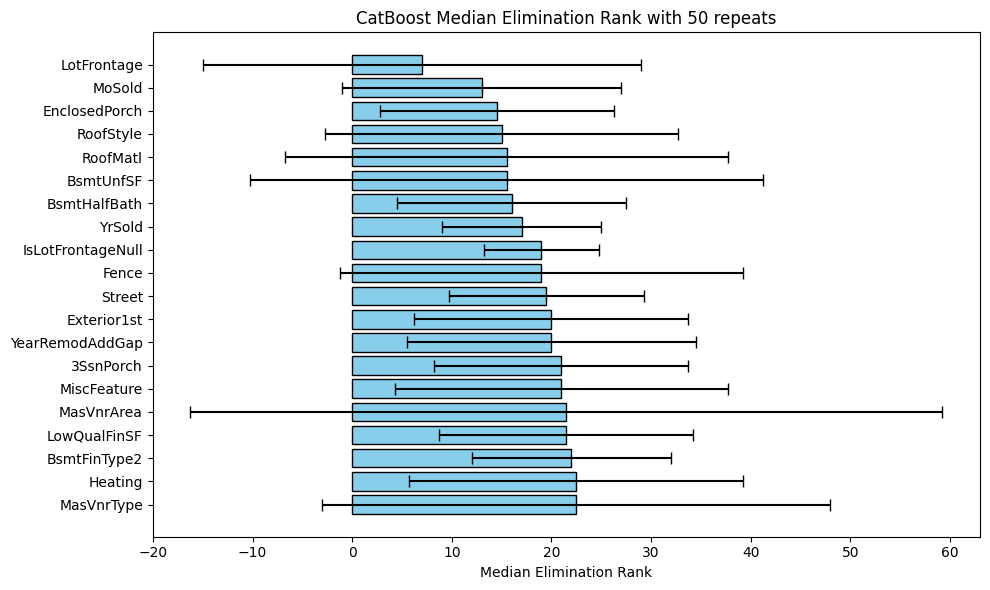

In [49]:
class RepeatedRFE:
    def __init__(self, n_repeats: int, features_to_keep: int=1):
        self.n_repeats = n_repeats
        self.features_to_keep = features_to_keep
        self.all_loss_curves = []
        self.removed_counts = None
        self.feature_elimination_ranks = {}

    def fit(self, X: pd.DataFrame, y: pd.DataFrame | pd.Series):

        self.feature_elimination_ranks = {col: [] for col in X}
        cat_vars = X.select_dtypes(["object", "category"]).columns.tolist()
        
        for _ in tqdm(range(self.n_repeats), desc="Running Feature Selection", total=self.n_repeats):

            X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=_)

            train_pool = Pool(data=X_train, label=y_train, cat_features=cat_vars)
            val_pool = Pool(data=X_val, label=y_val, cat_features=cat_vars)

            model = CatBoostRegressor(random_state=42 + _, verbose=0, task_type="GPU")

            summary = model.select_features(
                train_pool,
                features_for_select = X.columns.tolist(),
                eval_set = val_pool,
                num_features_to_select = self.features_to_keep, 
                steps = 1,
                algorithm = "RecursiveByShapValues",
                train_final_model = False,
                verbose = False,
                log_cout=open(os.devnull, "w"),  # <-- Captures the C++ print stream
                log_cerr=open(os.devnull, "w")   # <-- Captures errors/warnings if any
            )

            graph = summary.get("loss_graph")
            self.removed_counts = graph.get("removed_features_count")
            self.all_loss_curves.append(graph.get("loss_values"))

            eliminated_list = summary["eliminated_features_names"]
            for rank, feat in enumerate(eliminated_list):
                self.feature_elimination_ranks[feat].append(rank + 1)

        return self

    def get_graph_losses(self):
        
        all_loss_curves_np = np.array(self.all_loss_curves)
        mean_loss = all_loss_curves_np.mean(axis=0)
        std_loss = all_loss_curves_np.std(axis=0)
        best_idx = np.argmin(mean_loss)
        best_removed_count = self.removed_counts[best_idx]
        
        plt.figure(figsize=(10,6))
        for i, losses in enumerate(all_loss_curves_np):
            plt.plot(self.removed_counts, losses, color="red", alpha=0.5, label="Individual fits" if i == 0 else "")
        plt.plot(self.removed_counts, mean_loss, color="blue", label="Mean Validation Loss")
        plt.fill_between(self.removed_counts, mean_loss-std_loss, mean_loss+std_loss, color="b", alpha=0.15, label="+-1 Std.Dev")
        plt.axvline(best_removed_count, color="yellow", label=f"Minimum Mean Loss: {best_removed_count}")
        plt.title(f"Averaged CatBoost Feature Selection Curve ({self.n_repeats}-Fold CV)", fontsize=12)
        plt.xlabel("Number of Removed Features", fontsize=10)
        plt.ylabel("Validation Loss (RMSE)", fontsize=10)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend()
        plt.show()

        return None

    def get_ranking_stats(self):
        
        stats = []
        
        for feature, ranks in self.feature_elimination_ranks.items():
            if len(ranks) > 0:
                med = np.median(ranks)
                q25 = np.percentile(ranks, 25)
                q75 = np.percentile(ranks, 75)
                iqr = q75 - q25
                
                stats.append({
                    "Feature": feature,
                    "Elimination_Rank": ranks,
                    "Median_Elimination_Rank": med,
                    "IQR_Elimination_Rank": iqr,
                    "Times_Eliminated": len(ranks)
                })

        ranking_df = pd.DataFrame(stats).sort_values("Median_Elimination_Rank", ascending=False)
        
        return ranking_df

selector = RepeatedRFE(n_repeats=50, features_to_keep=1)
selector.fit(X_trans, y)

selector.get_graph_losses()

ranking_df = selector.get_ranking_stats().tail(20)

plt.figure(figsize=(10, 6))
plt.barh(
    ranking_df["Feature"],
    ranking_df["Median_Elimination_Rank"],
    xerr = ranking_df["IQR_Elimination_Rank"],
    capsize = 4,
    color = "skyblue",
    edgecolor = "black"
)
plt.xlabel(f"Median Elimination Rank")
plt.title(f"CatBoost Median Elimination Rank with {selector.n_repeats} repeats")
plt.tight_layout()
plt.show()

Running Feature Permutation: 100%|██████████| 50/50 [28:07<00:00, 33.74s/it]


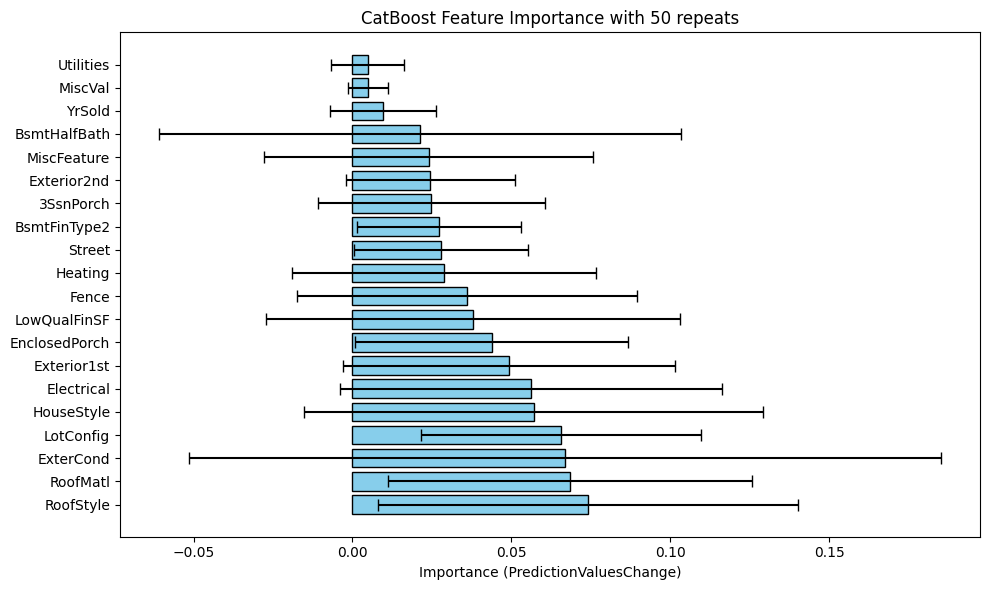

In [10]:
class FeaturePermutationImportanceCV:
    def __init__(self, n_repeats: int=10, method: str="PredictionValuesChange"):
        self.n_repeats = n_repeats
        self.method = method
        self.features_importance = {}
        self.std_features_importance = []

    def fit(self, X: pd.DataFrame, y: pd.DataFrame | pd.Series):

        cat_vars = X.select_dtypes(["object", "category"]).columns.tolist()
        all_vars = X.columns
        importances = []
        
        for _ in tqdm(range(self.n_repeats), desc="Running Feature Permutation", total=self.n_repeats):
            X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=_)

            train_pool = Pool(data=X_train, label=y_train, cat_features=cat_vars)
            val_pool = Pool(data=X_val, label=y_val, cat_features=cat_vars)

            model = CatBoostRegressor(random_state=42 + _, verbose=0, task_type="GPU")
            model.fit(train_pool)

            importance = model.get_feature_importance(val_pool, type=self.method)
            importances.append(importance)

        mean_importances = np.mean(importances, axis=0)
        std_importances = np.std(importances, axis=0)
        self.features_importance = {col: importance for col, importance in zip(all_vars, mean_importances)}
        self.std_features_importance = std_importances

        return self

    def get_importance_plot(self, n_features:int, ascending:bool=True):

        feature_names = self.features_importance.keys()
        importances = self.features_importance.values()
        std = self.std_features_importance
        
        feature_importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances,
            "Std": std
        }).sort_values(by='Importance', ascending=ascending)

        plot_df = feature_importance_df.head(n_features).iloc[::-1]
        
        plt.figure(figsize=(10, 6))
        plt.barh(
            plot_df["Feature"],
            plot_df["Importance"],
            xerr=plot_df["Std"],
            capsize=4,
            color="skyblue",
            edgecolor="black"
        )
        plt.xlabel(f"Importance ({self.method})")
        plt.title(f"CatBoost Feature Importance with {self.n_repeats} repeats")
        plt.tight_layout()
        plt.show()

        return None

fpi = FeaturePermutationImportanceCV(n_repeats=50)
fpi.fit(X_trans, y)
fpi.get_importance_plot(20)

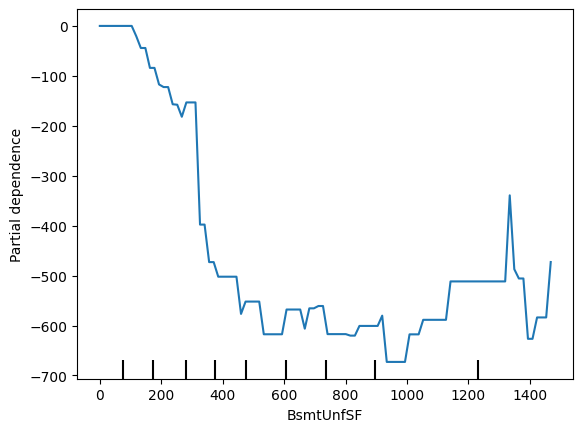

[0.12031108]


In [35]:
from sklearn.inspection import PartialDependenceDisplay
from sklearn.feature_selection import mutual_info_regression

feature = "BsmtUnfSF"

PDP = PartialDependenceDisplay.from_estimator(
    estimator = model,
    X = X_trans,
    #features = [(feature, "GrLivArea")],
    features = [feature],
    #categorical_features = [feature],
    kind = "average",
    centered = True
)
plt.show()

print(mutual_info_regression(X_trans[[feature]], y, discrete_features=False))

<Axes: xlabel='BsmtUnfSFRatio', ylabel='SalePrice'>

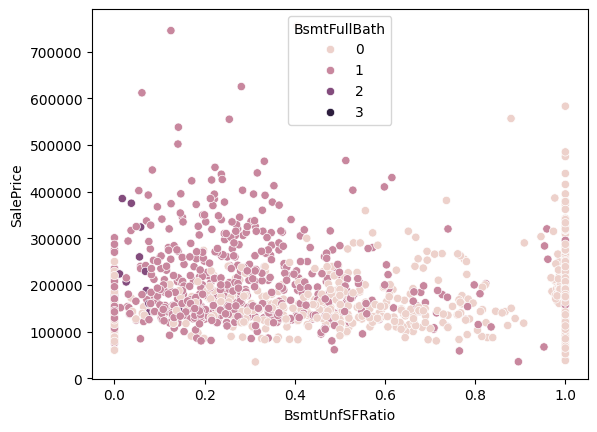

In [45]:
temp = X_trans.copy()
temp["BsmtUnfSFRatio"] = temp["BsmtUnfSF"] / temp["TotalBsmtSF"]

#display(temp.loc[temp["BsmtUnfSFRatio"] > 0.9, ["BsmtUnfSFRatio", "BsmtFullBath"]]).value_counts()

sns.scatterplot(data=temp, x="BsmtUnfSFRatio", y=y, hue="BsmtFullBath")

In [ ]:
plt.figure(figsize=(10,5))
sns.stripplot(x=X_trans["Electrical"], y=y)
plt.show()

In [ ]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_trans, y)
shap_interaction_values = explainer.shap_interaction_values(X_trans, y)

In [ ]:
shap.plots.scatter(shap_values[:, "LowQualFinSF"])

In [ ]:
shap.dependence_plot(
    ("MoSold", "GrLivArea"),
    shap_interaction_values,
    X_trans
)